In [1]:
import pandas as pd

In [2]:
df = pd.read_csv(r"transcripts_with_dates.csv")

In [3]:
df_main = df[df['earnings_call_date'].notnull()]

In [4]:
df_main.head()

,filepath,company_folder,year,quarter,ticker_abbrev,resolved_ticker,earnings_call_date
55,data_collection\NLP_Dataset\Airbus\2018_Q1_air...,Airbus,2018,Q1,AIR,AIR.PA,2018-04-26
56,data_collection\NLP_Dataset\Airbus\2019_Q1_air...,Airbus,2019,Q1,AIR,AIR.PA,2019-04-30
57,data_collection\NLP_Dataset\Airbus\2020_Q1_air...,Airbus,2020,Q1,AIR,AIR.PA,2020-04-28
58,data_collection\NLP_Dataset\Airbus\2021_Q1_air...,Airbus,2021,Q1,AIR,AIR.PA,2021-04-29
59,data_collection\NLP_Dataset\Airbus\2022_Q1_air...,Airbus,2022,Q1,AIR,AIR.PA,2022-05-04


In [5]:
df_main.shape

(806, 7)

In [6]:
from agent import Agent
from llms import predict, predict_from_text

W0826 10:11:11.507000 29820 torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
c:\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W0826 10:11:51.109000 29820 torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


In [7]:
from dotenv import load_dotenv

# Search for and load the .env file
load_dotenv()


True

In [8]:
idx = 10

In [ ]:
agent = Agent(provider="huggingface", model="deepseek-ai/DeepSeek-V4-Flash-0731")

C:\Users\varun\AppData\Roaming\Python\Python312\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\varun\.cache\huggingface\hub\models--deepseek-ai--DeepSeek-V4-Flash-0731. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Fetching 48 files:   0%| 

In [10]:
df_main.iloc[idx]["earnings_call_date"]

'2018-05-01'

In [11]:
path = df_main.iloc[idx]['filepath']
ticker = df_main.iloc[idx]['resolved_ticker']
year=df_main.iloc[idx]['earnings_call_date'][:4]
month=df_main.iloc[idx]['earnings_call_date'][5:7]
day=df_main.iloc[idx]['earnings_call_date'][8:]
day


'01'

In [13]:
import os
import pandas as pd
 
try:
    from tqdm.auto import tqdm
except ImportError:  # pragma: no cover - fallback if tqdm isn't installed
    class tqdm:  # minimal no-op stand-in with the same interface we use
        def __init__(self, iterable, *args, **kwargs):
            self.iterable = iterable
 
        def __iter__(self):
            return iter(self.iterable)
 
        def set_postfix(self, *args, **kwargs):
            pass
 
        def write(self, msg):
            print(msg)
 
        def close(self):
            pass
 
 
def run_predictions(
    df_main,
    agent,
    prompt_number,
    output_name,
    condense=False,
    get_probs=True,
    checkpoint_every=10,
    output_dir=".",
):
    """
    Run predict_from_text() over every row of df_main and save the results.
 
    Parameters
    ----------
    df_main : pd.DataFrame
        Source dataframe. Must contain 'filepath', 'resolved_ticker', and
        'earnings_call_date' (string, 'YYYY-MM-DD...') columns.
    agent : object
        The agent object passed straight through to predict_from_text.
    prompt_number : int
        Which prompt variant to use (0-4). Passed through to
        predict_from_text and also stored in the output for bookkeeping.
    output_name : str
        Base filename (no extension) for the checkpoint/output files.
        Results are written to f"{output_dir}/{output_name}.pkl" (full
        fidelity, since some result fields are DataFrames/dicts) and
        mirrored to f"{output_dir}/{output_name}.csv" (stringified,
        convenient for quick inspection).
    condense : bool
        Passed through to predict_from_text.
    get_probs : bool
        Passed through to predict_from_text.
    checkpoint_every : int
        Save progress to disk after every N newly-processed rows.
    output_dir : str
        Directory the checkpoint/output files live in. Created if needed.
 
    Returns
    -------
    pd.DataFrame
        The accumulated results (one row per df_main row processed so far).
        Columns: row_idx, ticker, filepath, year, month, day,
        prompt_number, reaction, price_dif, analyst_recs, result, probs,
        error.
 
    Notes
    -----
    - If a checkpoint file already exists for output_name, rows already
      recorded there are skipped, so re-running with the same output_name
      resumes rather than restarts.
    - If predict_from_text raises for a given row, the error is caught,
      logged to the 'error' column, and the loop continues on to the next
      row rather than aborting the whole run.
    """
    os.makedirs(output_dir, exist_ok=True)
    checkpoint_path = os.path.join(output_dir, f"{output_name}.pkl")
    csv_path = os.path.join(output_dir, f"{output_name}.csv")
 
    result_columns = [
        "row_idx", "ticker", "filepath", "year", "month", "day",
        "prompt_number", "reaction", "price_dif", "analyst_recs",
        "result", "probs", "error",
    ]
 
    # Resume from an existing checkpoint if present.
    if os.path.exists(checkpoint_path):
        results_df = pd.read_pickle(checkpoint_path)
        done_indices = set(results_df["row_idx"].tolist())
        print(f"Resuming '{output_name}': {len(done_indices)} row(s) already done.")
    else:
        results_df = pd.DataFrame(columns=result_columns)
        done_indices = set()
 
    n_rows = len(df_main)
    new_rows_since_checkpoint = 0
 
    # Iterating over the full range keeps the bar's total accurate; rows
    # already present in the checkpoint are skipped (fast) rather than
    # re-processed, so on a resume the bar zips quickly through the
    # already-done prefix before slowing down at the real work.
    pbar = tqdm(range(n_rows), desc=output_name, total=n_rows)
 
    for idx in pbar:
        if idx in done_indices:
            continue
 
        path = df_main.iloc[idx]["filepath"]
        ticker = df_main.iloc[idx]["resolved_ticker"]
        date_str = str(df_main.iloc[idx]["earnings_call_date"])
        year = date_str[:4]
        month = date_str[5:7]
        day = date_str[8:]
 
        pbar.set_postfix(ticker=ticker, refresh=False)
 
        row_result = {
            "row_idx": idx,
            "ticker": ticker,
            "filepath": path,
            "year": year,
            "month": month,
            "day": day,
            "prompt_number": prompt_number,
            "reaction": None,
            "price_dif": None,
            "analyst_recs": None,
            "result": None,
            "probs": None,
            "error": None,
        }
 
        try:
            reaction, price_dif, analyst_recs, result, probs = predict_from_text(
                agent,
                ticker,
                path,
                prompt_number=prompt_number,
                day=int(day),
                month=int(month),
                year=int(year),
                condense=condense,
                get_probs=get_probs,
            )
            row_result.update(
                {
                    "reaction": reaction,
                    "price_dif": price_dif,
                    "analyst_recs": analyst_recs,
                    "result": result,
                    "probs": probs,
                }
            )
        except Exception as e:
            row_result["error"] = str(e)
            pbar.set_postfix(ticker=ticker, error=True, refresh=False)
            pbar.write(f"[{idx + 1}/{n_rows}] ERROR for {ticker} ({path}): {e}")
 
        results_df = pd.concat(
            [results_df, pd.DataFrame([row_result])], ignore_index=True
        )
        new_rows_since_checkpoint += 1
 
        if new_rows_since_checkpoint >= checkpoint_every:
            results_df.to_pickle(checkpoint_path)
            results_df.to_csv(csv_path, index=False)
            new_rows_since_checkpoint = 0
            pbar.write(f"Checkpoint saved at row {idx + 1}/{n_rows} -> {checkpoint_path}")
 
    pbar.close()
 
    # Final save, in case the last batch was smaller than checkpoint_every.
    results_df.to_pickle(checkpoint_path)
    results_df.to_csv(csv_path, index=False)
    print(f"Done. {len(results_df)} row(s) saved to {checkpoint_path} (and {csv_path}).")
 
    return results_df
 

In [12]:
res = predict_from_text(agent, ticker,path, day=day, month=month, year=year, prompt_number=0, get_probs=False)
res

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


('sell',
 Price           Close       High        Low       Open   Volume
 Ticker            ALL        ALL        ALL        ALL      ALL
 Date                                                           
 2018-05-01  81.262291  81.262291  79.954817  80.765781  1547200
 2018-05-02  77.836357  81.080233  76.413025  80.931280  4938800
 2018-05-03  77.828087  78.208744  75.949617  77.315023  2695600
 2018-05-04  78.217003  78.721789  76.843326  77.290187  1681800
 2018-05-07  78.663872  79.036259  77.703954  78.258390  1729900,
 {'ticker': 'ALL',
  'as_of_date': '2018-05-01',
  'consensus': 'Hold',
  'disagreement': 0.41666666666666663,
  'counts': {'strong_buy': 0,
   'buy': 4,
   'hold': 7,
   'sell': 1,
   'strong_sell': 0,
   'unknown': 0},
  'firms_used': 12,
  'summary': "ALL as of 2018-05-01 (12 firms, 365-day lookback): StrongBuy=0, Buy=4, Hold=7, Sell=1, StrongSell=0. Consensus leans 'Hold', disagreement score=0.42",
  'raw':               GradeDate                     Firm       

In [ ]:
for prompt_number in range(5):
    run_predictions(df_main, agent, prompt_number=prompt_number, output_name=f"results/deep_seek_prompt_{prompt_number}", condense=False, get_probs=True, checkpoint_every=10, output_dir=".")

In [26]:
import pandas as pd
import logging
import time
import os
from tqdm import tqdm

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s"
)
logger = logging.getLogger(__name__)


def run_predictions(
    df_main: pd.DataFrame,
    agent,
    checkpoint_path: str = "checkpoint.csv",
    checkpoint_every: int = 20,
    probs_labels=("BUY", "SELL", "HOLD"),
    prompt_number: int = 0,
    get_probs: bool = True
) -> pd.DataFrame:

    result_cols = ["reaction", "price_dif", "result"] + [f"prob_{l}" for l in probs_labels]
    for col in result_cols:
        if col not in df_main.columns:
            df_main[col] = None

    # --- Resume from checkpoint if it exists ---
    start_idx = 0
    if os.path.exists(checkpoint_path):
        checkpoint_df = pd.read_csv(checkpoint_path)
        df_main.loc[checkpoint_df.index, result_cols] = checkpoint_df[result_cols]
        start_idx = checkpoint_df["result"].notna().sum()
        logger.info(f"Resuming from checkpoint: {start_idx} rows already completed.")

    total = len(df_main)
    already_done = df_main["result"].notna().sum()

    pbar = tqdm(
        total=total,
        initial=already_done,
        desc="Predicting",
        unit="row",
    )

    for i, idx in enumerate(df_main.index):
        if pd.notna(df_main.at[idx, "result"]):
            continue  # already done, skip

        row = df_main.loc[idx]

        path = row['filepath']
        ticker = row['resolved_ticker']
        earnings_date = row['earnings_call_date']
        year = earnings_date[:4]
        month = earnings_date[5:7]
        day = earnings_date[8:]

        try:
            t0 = time.time()
            reaction, price_dif, result, probs = predict_from_text(
                agent, ticker, path,
                day=day, month=month, year=year,
                prompt_number=prompt_number,
                get_probs=get_probs
            )
            elapsed = time.time() - t0

            df_main.at[idx, "reaction"] = reaction
            df_main.at[idx, "price_dif"] = price_dif
            df_main.at[idx, "result"] = result

            if probs:
                for label in probs_labels:
                    df_main.at[idx, f"prob_{label}"] = probs.get(label)

            logger.info(
                f"[{i+1}/{total}] idx={idx} ticker={ticker} result={result} "
                f"probs={probs} ({elapsed:.2f}s)"
            )
            pbar.set_postfix(ticker=ticker, result=result)

        except Exception as e:
            logger.error(f"[{i+1}/{total}] idx={idx} ticker={ticker} FAILED: {e}")
            df_main.at[idx, "result"] = "ERROR"
            pbar.set_postfix(ticker=ticker, result="ERROR")

        pbar.update(1)

        # --- Checkpoint periodically ---
        if (i + 1) % checkpoint_every == 0:
            df_main.to_csv(checkpoint_path, index=True)
            logger.info(f"Checkpoint saved at row {i+1}/{total} -> {checkpoint_path}")

    pbar.close()

    # --- Final save ---
    df_main.to_csv(checkpoint_path, index=True)
    logger.info(f"Done. Final results saved to {checkpoint_path}")

    return df_main

In [45]:
import pandas as pd
import logging
import time
import os
from tqdm import tqdm

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s"
)
logger = logging.getLogger(__name__)


def run_predictions_shrink(
    df_main: pd.DataFrame,
    agent,
    checkpoint_path: str = "checkpoint.csv",
    checkpoint_every: int = 20,
    probs_labels=("BUY", "SELL", "HOLD"),
    prompt_number: int = 0,
    get_probs: bool = True,
    factor = 1
) -> pd.DataFrame:

    result_cols = ["reaction", "price_dif", "result"] + [f"prob_{l}" for l in probs_labels]
    for col in result_cols:
        if col not in df_main.columns:
            df_main[col] = None

    # --- Resume from checkpoint if it exists ---
    start_idx = 0
    if os.path.exists(checkpoint_path):
        checkpoint_df = pd.read_csv(checkpoint_path)
        df_main.loc[checkpoint_df.index, result_cols] = checkpoint_df[result_cols]
        start_idx = checkpoint_df["result"].notna().sum()
        logger.info(f"Resuming from checkpoint: {start_idx} rows already completed.")

    total = len(df_main)
    already_done = df_main["result"].notna().sum()

    pbar = tqdm(
        total=total,
        initial=already_done,
        desc="Predicting",
        unit="row",
    )
    for i, idx in enumerate(df_main.index):
        if i % factor != 0:
            continue  # Skip rows based on the factor
        if pd.notna(df_main.at[idx, "result"]):
            continue  # already done, skip

        row = df_main.loc[idx]

        path = row['filepath']
        ticker = row['resolved_ticker']
        earnings_date = row['earnings_call_date']
        year = earnings_date[:4]
        month = earnings_date[5:7]
        day = earnings_date[8:]

        try:
            t0 = time.time()
            reaction, price_dif, result, probs = predict_from_text(
                agent, ticker, path,
                day=day, month=month, year=year,
                prompt_number=prompt_number,
                get_probs=get_probs
            )
            print("ran")
            elapsed = time.time() - t0

            df_main.at[idx, "reaction"] = reaction
            df_main.at[idx, "price_dif"] = price_dif
            df_main.at[idx, "result"] = result

            if probs:
                for label in probs_labels:
                    df_main.at[idx, f"prob_{label}"] = probs.get(label)

            logger.info(
                f"[{i+1}/{total}] idx={idx} ticker={ticker} result={result} "
                f"probs={probs} ({elapsed:.2f}s)"
            )
            pbar.set_postfix(ticker=ticker, result=result)

        except Exception as e:
            print(f"Error processing idx={idx}, ticker={ticker}: {e}")
            logger.error(f"[{i+1}/{total}] idx={idx} ticker={ticker} FAILED: {e}")
            df_main.at[idx, "result"] = "ERROR"
            pbar.set_postfix(ticker=ticker, result="ERROR")

        pbar.update(1)

        # --- Checkpoint periodically ---
        if (i + 1) % checkpoint_every == 0:
            df_main.to_csv(checkpoint_path, index=True)
            logger.info(f"Checkpoint saved at row {i+1}/{total} -> {checkpoint_path}")

    pbar.close()

    # --- Final save ---
    df_main.to_csv(checkpoint_path, index=True)
    logger.info(f"Done. Final results saved to {checkpoint_path}")

    return df_main

In [46]:
i=0
result_df = run_predictions(df_main, agent, checkpoint_path=f"gpt-5.6-luna-pro_{i}_expanded.csv", checkpoint_every=20, prompt_number=i, get_probs=False)

KeyError: '[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 316, 317, 318, 319, 320, 353, 367, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 507, 509, 511, 513, 514, 515, 517, 518, 519, 521, 522, 523, 524, 525, 526, 527, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538, 539, 540, 541, 542, 543, 544, 545, 546, 548, 552, 553, 554, 555, 556, 557, 558, 559, 560, 561, 562, 563, 564, 565, 566, 567, 568, 569, 601, 606, 607, 608, 718, 719, 720, 721, 723, 724, 725, 726, 727, 728

In [62]:
for i in range(5):
    result_df = run_predictions_shrink(df_main, agent, checkpoint_path=f"deepseek_{i}_shrink.csv", checkpoint_every=20, prompt_number=i, get_probs=False, factor=8)

2026-08-04 02:44:43,904 [ERROR] [9/806] idx=63 ticker=AIR.PA FAILED: 'charmap' codec can't decode byte 0x90 in position 1258: character maps to <undefined>


Error processing idx=63, ticker=AIR.PA: 'charmap' codec can't decode byte 0x90 in position 1258: character maps to <undefined>


[*********************100%***********************]  1 of 1 completed
2026-08-04 02:44:50,536 [INFO] HTTP Request: POST https://openrouter.ai/api/v1/chat/completions "HTTP/1.1 200 OK"
[*********************100%***********************]  1 of 1 completed
2026-08-04 02:45:21,763 [INFO] [17/806] idx=71 ticker=ALL result=Decision: 0
Rationale: Allstate reported strong Q3 2019 results, with adjusted EPS of $2.84, revenue above $11 billion, a 14.2% adjusted ROE, and improved underwriting margins. Property-liability premiums grew 5.8%, policy counts increased, and the company highlighted sustainable expense improvements and competitive advantages in homeowners insurance. The stock also showed a general upward trend in the preceding months, supported by solid fundamentals, aggressive share repurchases, and a strong capital position. Given the positive earnings trajectory and management's confident outlook, the stock is likely to be higher two months after the earnings call. probs={} (37.86s)

Pr

ran


[*********************100%***********************]  1 of 1 completed
2026-08-04 02:45:23,440 [INFO] HTTP Request: POST https://openrouter.ai/api/v1/chat/completions "HTTP/1.1 200 OK"
[*********************100%***********************]  1 of 1 completed
2026-08-04 02:45:56,007 [INFO] [25/806] idx=79 ticker=ALL result=Decision: 1  
Rationale: The Q3 2021 earnings call revealed deteriorating auto insurance underwriting results due to higher claim frequency and severe inflation in used-car and parts costs. The overall reported combined ratio worsened to 105.3, and Allstate had to strengthen prior-year reserves, indicating near-term profitability pressure. Although management is raising rates, those increases take roughly six months to earn into results, so the benefit will likely not materialize within the two-month investment horizon. The stock has also been trending downward in recent weeks, consistent with investor concerns about elevated loss costs and margin compression. Therefore, the

...

[*********************100%***********************]  1 of 1 completed
2026-08-04 10:06:53,233 [INFO] HTTP Request: POST https://openrouter.ai/api/v1/chat/completions "HTTP/1.1 200 OK"
[*********************100%***********************]  1 of 1 completed
2026-08-04 10:08:34,044 [INFO] [793/806] idx=1117 ticker=DIS result=Decision: 1 (SELL).  
Rationale: The earnings call highlights strong Disney+ subscriber growth but also notes continued COVID-related disruptions to parks, including Disneyland closure and reduced capacity. The two-month outlook from the call is clouded by these headwinds, and the provided price data shows a clear downward trend from mid-March ($190.77) to mid-May ($172.44), indicating the stock likely declined over the relevant horizon. Therefore, the stock is expected to be lower two months after the call, so selling is the appropriate action. probs={} (102.47s)

Predicting:  13%|█▎        | 101/806 [7:23:50<17:15:23, 88.12s/row, result=Decision: 1 (SELL).  
Predicting:

ran


[*********************100%***********************]  1 of 1 completed
2026-08-04 10:08:41,586 [INFO] HTTP Request: POST https://openrouter.ai/api/v1/chat/completions "HTTP/1.1 200 OK"
[*********************100%***********************]  1 of 1 completed
2026-08-04 10:14:42,532 [INFO] [801/806] idx=1125 ticker=DIS result=Decision: 0 (Buy). Rationale: The earnings call highlights solid strategic execution: streaming losses are narrowing, cost cuts are on track to exceed $5.5 billion, pricing power is evident (price increases we only minimal subscriber losses), and the parks segment remains a strong growth driver. The planned integration of Hulu into Disney+ and ad-tier expansion in Europe are positive catalysts for engagement and advertising revenue. Despite near-term headwinds in linear networks and advertising softness, the company’s forward guidance is optimistic, and the stock appears undervalued relative to its long-term upside. Past price data shows volatility but a stabilization aro

ran


2026-08-04 10:14:42,843 [INFO] Done. Final results saved to deepseek_0_shrink.csv
Predicting:  13%|█▎        | 103/806 [00:00<?, ?row/s]
2026-08-04 10:14:43,478 [INFO] Done. Final results saved to deepseek_1_shrink.csv
Predicting:  13%|█▎        | 103/806 [00:00<?, ?row/s]
2026-08-04 10:14:43,864 [INFO] Done. Final results saved to deepseek_2_shrink.csv
Predicting:  13%|█▎        | 103/806 [00:00<?, ?row/s]
2026-08-04 10:14:44,163 [INFO] Done. Final results saved to deepseek_3_shrink.csv
Predicting:  13%|█▎        | 103/806 [00:00<?, ?row/s]
2026-08-04 10:14:44,443 [INFO] Done. Final results saved to deepseek_4_shrink.csv


In [15]:
result_df.shape

(806, 13)

In [20]:
results2 = pd.read_csv("gpt_4o_1_expanded.csv")
results2.shape

(806, 14)

In [21]:
results2.head()

,Unnamed: 0,filepath,company_folder,year,quarter,ticker_abbrev,resolved_ticker,earnings_call_date,reaction,price_dif,result,prob_BUY,prob_SELL,prob_HOLD
0,55,data_collection\NLP_Dataset\Airbus\2018_Q1_air...,Airbus,2018,Q1,AIR,AIR.PA,2018-04-26,buy,Ticker\nAIR.PA 1.230347\ndtype: float64,Decision: 0 (BUY). \n\nRationale: Based on the...,99.87,0.00,0.13
1,56,data_collection\NLP_Dataset\Airbus\2019_Q1_air...,Airbus,2019,Q1,AIR,AIR.PA,2019-04-30,buy,Ticker\nAIR.PA 2.568825\ndtype: float64,**Decision: 0 (BUY)**\n\n**Rationale:** Based ...,100.00,0.00,0.00
2,57,data_collection\NLP_Dataset\Airbus\2020_Q1_air...,Airbus,2020,Q1,AIR,AIR.PA,2020-04-28,sell,Ticker\nAIR.PA 8.256916\ndtype: float64,Decision: 1 (SELL). \n\nRationale: Based on th...,0.00,99.94,0.06
3,58,data_collection\NLP_Dataset\Airbus\2021_Q1_air...,Airbus,2021,Q1,AIR,AIR.PA,2021-04-29,buy,Ticker\nAIR.PA 6.513794\ndtype: float64,**Decision: 0 (BUY)**\n\n**Rationale:** Based ...,67.75,0.24,32.00
4,59,data_collection\NLP_Dataset\Airbus\2022_Q1_air...,Airbus,2022,Q1,AIR,AIR.PA,2022-05-04,sell,Ticker\nAIR.PA -6.830521\ndtype: float64,**Decision: 1 (SELL).**\n\n**Rationale:** Base...,0.01,90.46,9.53


In [17]:
result_df.head()

,filepath,company_folder,year,quarter,ticker_abbrev,resolved_ticker,earnings_call_date,reaction,price_dif,result,prob_BUY,prob_SELL,prob_HOLD
55,data_collection\NLP_Dataset\Airbus\2018_Q1_air...,Airbus,2018,Q1,AIR,AIR.PA,2018-04-26,buy,Ticker AIR.PA 1.230347 dtype: float64,Decision: 0 (BUY). \n\nRationale: Based on the...,99.87,0.0,0.13
56,data_collection\NLP_Dataset\Airbus\2019_Q1_air...,Airbus,2019,Q1,AIR,AIR.PA,2019-04-30,buy,Ticker AIR.PA 2.568825 dtype: float64,**Decision: 0 (BUY)**\n\n**Rationale:** Based ...,100.0,0.0,0.0
57,data_collection\NLP_Dataset\Airbus\2020_Q1_air...,Airbus,2020,Q1,AIR,AIR.PA,2020-04-28,sell,Ticker AIR.PA 8.256916 dtype: float64,Decision: 1 (SELL). \n\nRationale: Based on th...,0.0,99.94,0.06
58,data_collection\NLP_Dataset\Airbus\2021_Q1_air...,Airbus,2021,Q1,AIR,AIR.PA,2021-04-29,buy,Ticker AIR.PA 6.513794 dtype: float64,**Decision: 0 (BUY)**\n\n**Rationale:** Based ...,67.75,0.24,32.0
59,data_collection\NLP_Dataset\Airbus\2022_Q1_air...,Airbus,2022,Q1,AIR,AIR.PA,2022-05-04,sell,Ticker AIR.PA -6.830521 dtype: float64,**Decision: 1 (SELL).**\n\n**Rationale:** Base...,0.01,90.46,9.53


In [18]:
results2.head()

,Unnamed: 0,filepath,company_folder,year,quarter,ticker_abbrev,resolved_ticker,earnings_call_date,reaction,price_dif,result,prob_BUY,prob_SELL,prob_HOLD
0,55,data_collection\NLP_Dataset\Airbus\2018_Q1_air...,Airbus,2018,Q1,AIR,AIR.PA,2018-04-26,buy,Ticker\nAIR.PA 1.230362\ndtype: float64,Decision: 0 (BUY). \n\nRationale: Based on the...,99.99,0.00,0.01
1,56,data_collection\NLP_Dataset\Airbus\2019_Q1_air...,Airbus,2019,Q1,AIR,AIR.PA,2019-04-30,buy,Ticker\nAIR.PA 2.56881\ndtype: float64,**Decision: 0 (BUY).**\n\n**Rationale:** \n\nB...,100.00,0.00,0.00
2,57,data_collection\NLP_Dataset\Airbus\2020_Q1_air...,Airbus,2020,Q1,AIR,AIR.PA,2020-04-28,sell,Ticker\nAIR.PA 8.256912\ndtype: float64,Decision: 1 (SELL). \n\nRationale: The earning...,0.00,99.59,0.41
3,58,data_collection\NLP_Dataset\Airbus\2021_Q1_air...,Airbus,2021,Q1,AIR,AIR.PA,2021-04-29,buy,Ticker\nAIR.PA 6.513786\ndtype: float64,**Decision: 0 (BUY)**\n\n**Rationale:** The st...,95.79,0.01,4.21
4,59,data_collection\NLP_Dataset\Airbus\2022_Q1_air...,Airbus,2022,Q1,AIR,AIR.PA,2022-05-04,buy,Ticker\nAIR.PA -6.830536\ndtype: float64,Decision: 0 (BUY). \n\nRationale: Based on the...,52.28,1.58,46.14


In [22]:
import re

DECISION_MAP = {"0": "BUY", "1": "SELL", "2": "HOLD"}

def extract_decision(text: str):
    """
    Extracts the decision digit (0/1/2) from text formatted as:
      - "Decision: 1"
      - "**Decision: 1**"
      - "**Decision:** 1"
      - "Decision:1" (no space)
    Returns "BUY", "SELL", "HOLD", or None if not found / not recognized.
    """
    if not isinstance(text, str):
        return None

    # Matches "Decision" optionally wrapped/preceded by *, then ":", optional *,
    # optional whitespace, then the digit
    pattern = r"\*{0,2}Decision\*{0,2}\s*:\s*\*{0,2}\s*([0-2])"
    match = re.search(pattern, text, re.IGNORECASE)

    if not match:
        return None

    digit = match.group(1)
    return DECISION_MAP.get(digit)

In [23]:
results2["decision"] = results2["result"].apply(extract_decision)

In [24]:
results2.head()

,Unnamed: 0,filepath,company_folder,year,quarter,ticker_abbrev,resolved_ticker,earnings_call_date,reaction,price_dif,result,prob_BUY,prob_SELL,prob_HOLD,decision
0,55,data_collection\NLP_Dataset\Airbus\2018_Q1_air...,Airbus,2018,Q1,AIR,AIR.PA,2018-04-26,buy,Ticker\nAIR.PA 1.230347\ndtype: float64,Decision: 0 (BUY). \n\nRationale: Based on the...,99.87,0.00,0.13,BUY
1,56,data_collection\NLP_Dataset\Airbus\2019_Q1_air...,Airbus,2019,Q1,AIR,AIR.PA,2019-04-30,buy,Ticker\nAIR.PA 2.568825\ndtype: float64,**Decision: 0 (BUY)**\n\n**Rationale:** Based ...,100.00,0.00,0.00,BUY
2,57,data_collection\NLP_Dataset\Airbus\2020_Q1_air...,Airbus,2020,Q1,AIR,AIR.PA,2020-04-28,sell,Ticker\nAIR.PA 8.256916\ndtype: float64,Decision: 1 (SELL). \n\nRationale: Based on th...,0.00,99.94,0.06,SELL
3,58,data_collection\NLP_Dataset\Airbus\2021_Q1_air...,Airbus,2021,Q1,AIR,AIR.PA,2021-04-29,buy,Ticker\nAIR.PA 6.513794\ndtype: float64,**Decision: 0 (BUY)**\n\n**Rationale:** Based ...,67.75,0.24,32.00,BUY
4,59,data_collection\NLP_Dataset\Airbus\2022_Q1_air...,Airbus,2022,Q1,AIR,AIR.PA,2022-05-04,sell,Ticker\nAIR.PA -6.830521\ndtype: float64,**Decision: 1 (SELL).**\n\n**Rationale:** Base...,0.01,90.46,9.53,SELL


In [25]:
counts = results2["decision"].value_counts()
print(counts)

# Percentages
percentages = results2["decision"].value_counts(normalize=True) * 100
print(percentages.round(2))

decision
BUY     528
SELL     66
HOLD     27
Name: count, dtype: int64
decision
BUY     85.02
SELL    10.63
HOLD     4.35
Name: proportion, dtype: float64


In [27]:
results1 = pd.read_csv("gpt_4o_neutral_expanded.csv")

In [30]:
results1["decision"] = results1["result"].apply(extract_decision)

In [ ]:
results1["decision"] = results1["result"].apply(extract_decision)
counts = results1["decision"].value_counts()
print(counts)

# Percentages
percentages = results1["decision"].value_counts(normalize=True) * 100
print(percentages.round(2))

decision
BUY     710
SELL     48
HOLD     11
Name: count, dtype: int64
decision
BUY     92.33
SELL     6.24
HOLD     1.43
Name: proportion, dtype: float64


In [32]:
results3 = pd.read_csv("gpt_4o_3_expanded.csv")
results3["decision"] = results3["result"].apply(extract_decision)
counts = results3["decision"].value_counts()
print(counts)

# Percentages
percentages = results3["decision"].value_counts(normalize=True) * 100
print(percentages.round(2))

decision
BUY     528
SELL     66
HOLD     27
Name: count, dtype: int64
decision
BUY     85.02
SELL    10.63
HOLD     4.35
Name: proportion, dtype: float64


In [33]:
results4 = pd.read_csv("gpt_4o_4_expanded.csv")
results4["decision"] = results4["result"].apply(extract_decision)
counts = results4["decision"].value_counts()
print(counts)

# Percentages
percentages = results4["decision"].value_counts(normalize=True) * 100
print(percentages.round(2))

decision
BUY     528
SELL     66
HOLD     27
Name: count, dtype: int64
decision
BUY     85.02
SELL    10.63
HOLD     4.35
Name: proportion, dtype: float64


In [34]:
results2 = pd.read_csv("gpt_4o_2_expanded.csv")
results2["decision"] = results2["result"].apply(extract_decision)
counts = results2["decision"].value_counts()
print(counts)

# Percentages
percentages = results2["decision"].value_counts(normalize=True) * 100
print(percentages.round(2))

decision
BUY     528
SELL     66
HOLD     27
Name: count, dtype: int64
decision
BUY     85.02
SELL    10.63
HOLD     4.35
Name: proportion, dtype: float64


In [35]:
from transformers import AutoTokenizer, pipeline
import pandas as pd
from tqdm import tqdm

tokenizer = AutoTokenizer.from_pretrained("yiyanghkust/finbert-tone")
sentiment_pipe = pipeline(
    "text-classification",
    model="yiyanghkust/finbert-tone",
    tokenizer=tokenizer,
)

def chunk_text(text, max_tokens=512, stride=50):
    tokens = tokenizer.encode(text, truncation=False)
    chunks = []
    for i in range(0, len(tokens), max_tokens - stride):
        chunk = tokenizer.decode(tokens[i:i + max_tokens], skip_special_tokens=True)
        chunks.append(chunk)
        if i + max_tokens >= len(tokens):
            break
    return chunks

def get_full_sentiment_from_path(path):
    try:
        with open(path, "r", encoding="utf-8", errors="replace") as f:
            text = f.read()
    except Exception as e:
        return None, None

    if not text.strip():
        return None, None

    chunks = chunk_text(text)
    results = sentiment_pipe(chunks, truncation=True, max_length=512)

    # finbert-tone labels: Neutral, Positive, Negative
    label_scores = {"Positive": 0, "Negative": 0, "Neutral": 0}
    for r in results:
        label_scores[r["label"]] += r["score"]

    n = len(results)
    avg_scores = {k: v / n for k, v in label_scores.items()}
    final_label = max(avg_scores, key=avg_scores.get)

    return final_label, avg_scores[final_label]

tqdm.pandas()
results1[["sentiment_label", "sentiment_score"]] = results1["filepath"].progress_apply(
    lambda p: pd.Series(get_full_sentiment_from_path(p))
)

2026-07-28 09:55:48,324 [INFO] HTTP Request: HEAD https://huggingface.co/yiyanghkust/finbert-tone/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-28 09:55:48,401 [INFO] HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/yiyanghkust/finbert-tone/4921590d3c0c3832c0efea24c8381ce0bda7844b/config.json "HTTP/1.1 200 OK"
2026-07-28 09:55:48,469 [INFO] HTTP Request: GET https://huggingface.co/api/resolve-cache/models/yiyanghkust/finbert-tone/4921590d3c0c3832c0efea24c8381ce0bda7844b/config.json "HTTP/1.1 200 OK"
C:\Users\varun\AppData\Roaming\Python\Python312\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\varun\.cache\huggingface\hub\models--yiyanghkust--finbert-tone. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by se

ValueError: Couldn't instantiate the backend tokenizer from one of: 
(1) a `tokenizers` library serialization file, 
(2) a slow tokenizer instance to convert or 
(3) an equivalent slow tokenizer class to instantiate and convert. 
You need to have sentencepiece or tiktoken installed to convert a slow tokenizer to a fast one.

In [37]:
results1.head()

,Unnamed: 0,filepath,company_folder,year,quarter,ticker_abbrev,resolved_ticker,earnings_call_date,reaction,price_dif,result,prob_BUY,prob_SELL,prob_HOLD,decision
0,55,data_collection\NLP_Dataset\Airbus\2018_Q1_air...,Airbus,2018,Q1,AIR,AIR.PA,2018-04-26,buy,Ticker\nAIR.PA 1.230362\ndtype: float64,Decision: 0 (BUY). \n\nRationale: Based on the...,99.99,0.00,0.01,BUY
1,56,data_collection\NLP_Dataset\Airbus\2019_Q1_air...,Airbus,2019,Q1,AIR,AIR.PA,2019-04-30,buy,Ticker\nAIR.PA 2.56881\ndtype: float64,**Decision: 0 (BUY).**\n\n**Rationale:** \n\nB...,100.00,0.00,0.00,BUY
2,57,data_collection\NLP_Dataset\Airbus\2020_Q1_air...,Airbus,2020,Q1,AIR,AIR.PA,2020-04-28,sell,Ticker\nAIR.PA 8.256912\ndtype: float64,Decision: 1 (SELL). \n\nRationale: The earning...,0.00,99.59,0.41,SELL
3,58,data_collection\NLP_Dataset\Airbus\2021_Q1_air...,Airbus,2021,Q1,AIR,AIR.PA,2021-04-29,buy,Ticker\nAIR.PA 6.513786\ndtype: float64,**Decision: 0 (BUY)**\n\n**Rationale:** The st...,95.79,0.01,4.21,BUY
4,59,data_collection\NLP_Dataset\Airbus\2022_Q1_air...,Airbus,2022,Q1,AIR,AIR.PA,2022-05-04,buy,Ticker\nAIR.PA -6.830536\ndtype: float64,Decision: 0 (BUY). \n\nRationale: Based on the...,52.28,1.58,46.14,BUY


In [38]:
import re

def extract_float(val):
    if pd.isna(val):
        return None
    if isinstance(val, (int, float)):
        return float(val)
    if isinstance(val, str):
        match = re.search(r"-?\d+\.?\d*", val)
        if match:
            return float(match.group())
    return None

results1["price_dif"] = results1["price_dif"].apply(extract_float)

In [39]:
def check_correct(row):
    score = row["price_dif"]
    decision = row["decision"]

    if pd.isna(score) or pd.isna(decision):
        return 0

    if score > 1 and decision == "BUY":
        return 1
    elif score < -1 and decision == "SELL":
        return 1
    elif -1 <= score <= 1 and decision == "HOLD":
        return 1
    else:
        return 0

results1["correct"] = results1.apply(check_correct, axis=1)

In [40]:
results1.head()

,Unnamed: 0,filepath,company_folder,year,quarter,ticker_abbrev,resolved_ticker,earnings_call_date,reaction,price_dif,result,prob_BUY,prob_SELL,prob_HOLD,decision,correct
0,55,data_collection\NLP_Dataset\Airbus\2018_Q1_air...,Airbus,2018,Q1,AIR,AIR.PA,2018-04-26,buy,1.230362,Decision: 0 (BUY). \n\nRationale: Based on the...,99.99,0.00,0.01,BUY,1
1,56,data_collection\NLP_Dataset\Airbus\2019_Q1_air...,Airbus,2019,Q1,AIR,AIR.PA,2019-04-30,buy,2.568810,**Decision: 0 (BUY).**\n\n**Rationale:** \n\nB...,100.00,0.00,0.00,BUY,1
2,57,data_collection\NLP_Dataset\Airbus\2020_Q1_air...,Airbus,2020,Q1,AIR,AIR.PA,2020-04-28,sell,8.256912,Decision: 1 (SELL). \n\nRationale: The earning...,0.00,99.59,0.41,SELL,0
3,58,data_collection\NLP_Dataset\Airbus\2021_Q1_air...,Airbus,2021,Q1,AIR,AIR.PA,2021-04-29,buy,6.513786,**Decision: 0 (BUY)**\n\n**Rationale:** The st...,95.79,0.01,4.21,BUY,1
4,59,data_collection\NLP_Dataset\Airbus\2022_Q1_air...,Airbus,2022,Q1,AIR,AIR.PA,2022-05-04,buy,-6.830536,Decision: 0 (BUY). \n\nRationale: Based on the...,52.28,1.58,46.14,BUY,0


                accuracy_%    n
confidence_bin                 
0-40             33.333333    3
40-50            28.571429    7
50-60            41.176471   17
60-70            43.750000   16
70-80            36.363636   11
80-90            42.105263   19
90-100           50.000000  696


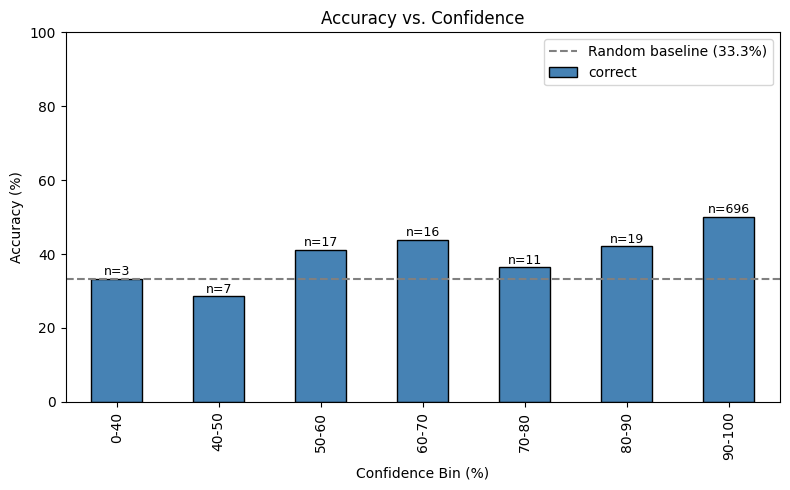

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Assuming "confidence" is the probability of the chosen decision (e.g. max of prob_BUY/prob_SELL/prob_HOLD)
# If you don't have this column yet, derive it:
results1["confidence"] = results1[["prob_BUY", "prob_SELL", "prob_HOLD"]].max(axis=1)

# Bin confidence into buckets
bins = [0, 40, 50, 60, 70, 80, 90, 100]
labels = ["0-40", "40-50", "50-60", "60-70", "70-80", "80-90", "90-100"]
results1["confidence_bin"] = pd.cut(results1["confidence"], bins=bins, labels=labels, include_lowest=True)

# Accuracy per bin
accuracy_by_bin = results1.groupby("confidence_bin", observed=True)["correct"].mean() * 100
counts_by_bin = results1.groupby("confidence_bin", observed=True)["correct"].count()

print(pd.DataFrame({"accuracy_%": accuracy_by_bin, "n": counts_by_bin}))

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
accuracy_by_bin.plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")

ax.set_xlabel("Confidence Bin (%)")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy vs. Confidence")
ax.set_ylim(0, 100)
ax.axhline(100 / 3, color="gray", linestyle="--", label="Random baseline (33.3%)")
ax.legend()

# Annotate bar counts
for i, (acc, n) in enumerate(zip(accuracy_by_bin, counts_by_bin)):
    if pd.notna(acc):
        ax.text(i, acc + 1, f"n={n}", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig("accuracy_vs_confidence.png", dpi=150)
plt.show()